# Experiment 3: Model Ensemble — Combining TF-IDF and XLM-RoBERTa

### Motivation

TF-IDF and XLM-RoBERTa represent text differently.

TF-IDF captures lexical patterns through word and character n-grams, while XLM-RoBERTa captures contextual and semantic relationships.

Although the encoder outperforms TF-IDF individually, the models may make different mistakes. Combining their predictions could improve classification robustness, particularly for the challenging `human` and `fusion` classes.

In our earlier experiment, equal-weight averaging improved a two-epoch XLM-RoBERTa model. However, we have since obtained a stronger encoder checkpoint from epoch 4.

We now investigate whether ensembling still provides benefits when the stronger model is used.

### Hypothesis

Combining the probability predictions of TF-IDF Logistic Regression and XLM-RoBERTa may improve validation macro-F1 compared with using the best encoder alone.

Weighted averaging may outperform equal-weight averaging because the models differ in predictive performance and confidence.

### Experimental Design

We compare:

1. TF-IDF Logistic Regression as a baseline.
2. XLM-RoBERTa epoch 4 as the reference encoder.
3. Equal-weight probability averaging.
4. Weighted probability averaging.
5. Optional calibrated probability averaging, if calibration can be evaluated without inappropriate data reuse.

The experiment uses the same 8,000 validation texts and the already saved model probabilities.

No models are retrained.

### Evaluation

We compare validation macro-F1, accuracy, per-class precision/recall/F1, confusion matrices, and complementary prediction errors.

We focus particularly on whether ensembling improves `fusion` classification without reducing overall performance.

## 2. Hypothesis and reference models

| Model | Validation macro-F1 |
|---|---|
| TF-IDF + Logistic Regression (C=3) | 0.8644 |
| XLM-RoBERTa (old encoder, epoch 2) - **not used here** | 0.8907 |
| Old ensemble 50/50 (with the epoch-2 encoder) - **not reused** | 0.9026 |
| **XLM-RoBERTa (best checkpoint, epoch 4)** - reference encoder | **0.9049** |

**Kaggle inputs (Add Input, then *Notebook Output Files* or a dataset made from the outputs):**
1. the output of the **TF-IDF baseline notebook**: the file `tfidf_probs.npz`;
2. the output of the **epoch-4 encoder notebook**: `encoder_outputs/xlmr_probs.npz` (and, if present, `run_config.json` next to it);
3. the **competition data** (`train.csv`, `test.csv`, `sample_submission.csv`) - needed to rebuild the validation split and verify ids.

Only CPU is needed; no model is trained or fine-tuned. If more than one matching archive is attached the notebook stops and asks for an explicit path (`TFIDF_PATH` / `XLMR_PATH`).

## 3. Imports and configuration

In [1]:
import os, glob, json, hashlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.stats import binomtest
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")

# ---------------- configuration ----------------
SEED, N_SUB, VAL_FRAC = 42, 40_000, 0.2
EXPECTED_FINGERPRINT = "97fed7e0aa8163e74359d495ffc4a025"
CLASSES = ["human", "ai", "fusion"]; label2id = {c: i for i, c in enumerate(CLASSES)}; id2label = {i: c for c, i in label2id.items()}
EXPECTED_F1 = {"tfidf": 0.8644, "xlmr": 0.9049}; F1_TOL = 0.003
TFIDF_PATH, XLMR_PATH = None, None                 # explicit paths override the search (required if several archives are found)
WEIGHTS = np.round(np.arange(0.0, 1.0001, 0.05), 2)  # weight of XLM-R; 0 = TF-IDF only, 1 = XLM-R only
N_REPEATS, N_BOOT, ECE_BINS, MIN_N = 100, 2000, 15, 100
STRICT_IDS = False                                 # True: stop if an archive carries no ids (see section 5 for what is verified instead)
OUT_DIR = "/kaggle/working/experiment_3_outputs" if os.path.isdir("/kaggle/working") else "./experiment_3_outputs"; os.makedirs(OUT_DIR, exist_ok=True)
rng_global = np.random.default_rng(SEED)

## 4. Load datasets and validate split
The competition files are used only to rebuild the validation ids (same code as the baseline and encoder notebooks), to verify the fingerprint, and for metadata (language, domain, length) in the error analysis.

In [2]:
_hits = glob.glob("/kaggle/input/**/train.csv", recursive=True) + glob.glob("./**/train.csv", recursive=True)
assert _hits, "train.csv not found: add the competition via 'Add Input'"
DATA_DIR = os.path.dirname(_hits[0])
train = pd.read_csv(f"{DATA_DIR}/train.csv", dtype={"id": str}); test = pd.read_csv(f"{DATA_DIR}/test.csv", dtype={"id": str}); sub_tmpl = pd.read_csv(f"{DATA_DIR}/sample_submission.csv", dtype={"id": str})
for d in (train, test): d["text"] = d["text"].fillna("").astype(str)
assert train.id.is_unique and test.id.is_unique and len(test) == len(sub_tmpl) == 25000 and set(sub_tmpl.label.unique()) <= set(CLASSES)

sub = train.sample(N_SUB, random_state=SEED).reset_index(drop=True)
tr_df, va_df = train_test_split(sub, test_size=VAL_FRAC, random_state=SEED, stratify=sub.label + "_" + sub.lang)
va_df = va_df.reset_index(drop=True); yva = va_df.label.map(label2id).values
FINGERPRINT = hashlib.md5(",".join(va_df.id).encode()).hexdigest()
assert len(va_df) == 8000 and va_df.id.is_unique
assert FINGERPRINT == EXPECTED_FINGERPRINT, f"validation split differs from the reference runs: {FINGERPRINT}"
va_df["n_words"] = va_df.text.str.split().str.len()
REF_VA_IDS, REF_TE_IDS = va_df.id.tolist(), test.id.tolist()
print("validation fingerprint OK:", FINGERPRINT, "| validation shares:", va_df.label.value_counts(normalize=True).round(3).to_dict())

validation fingerprint OK: 97fed7e0aa8163e74359d495ffc4a025 | validation shares: {'ai': 0.449, 'fusion': 0.307, 'human': 0.244}


## 5. Load saved probability predictions

In [3]:
def find_archive(name, explicit, hint):
    if explicit:
        assert os.path.isfile(explicit), f"{explicit} does not exist"; return explicit
    hits = sorted(set(glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"./**/{name}", recursive=True)))
    if not hits: raise FileNotFoundError(f"'{name}' not found under /kaggle/input. Attach {hint} with 'Add Input'.")
    if len(hits) > 1: raise RuntimeError(f"Several '{name}' files found: {hits}. Set the explicit path (TFIDF_PATH / XLMR_PATH) to the correct one; none was picked automatically.")
    return hits[0]

TFIDF_FILE = find_archive("tfidf_probs.npz", TFIDF_PATH, "the output of the TF-IDF baseline notebook (tfidf_probs.npz)")
XLMR_FILE = find_archive("xlmr_probs.npz", XLMR_PATH, "the output of the epoch-4 encoder notebook (encoder_outputs/xlmr_probs.npz)")
print("TF-IDF archive:", TFIDF_FILE); print("XLM-R archive :", XLMR_FILE)
zt, zx = np.load(TFIDF_FILE, allow_pickle=True), np.load(XLMR_FILE, allow_pickle=True)
print("keys TF-IDF:", list(zt.keys()), "| keys XLM-R:", list(zx.keys()))
for z, need, nm in [(zt, ["P_va", "P_te", "yva"], "TF-IDF"), (zx, ["va_ids", "test_ids", "yva", "P_va", "P_te", "classes"], "XLM-R")]:
    miss = [k for k in need if k not in z]; assert not miss, f"{nm} archive lacks {miss}; it contains {list(z.keys())}"

# the encoder archive must come from the epoch-4 run
for d in (os.path.dirname(XLMR_FILE), os.path.dirname(os.path.dirname(XLMR_FILE))):
    rc = os.path.join(d, "run_config.json")
    if os.path.exists(rc):
        cfg = json.load(open(rc)); assert cfg.get("best_epoch") == 4, f"encoder run in {rc} has best epoch {cfg.get('best_epoch')}, expected 4 (wrong encoder output attached?)"
        print("run_config.json:", rc, "-> best epoch", cfg["best_epoch"], "| val fingerprint:", cfg.get("val_id_fingerprint")); break
else: print("no run_config.json next to the XLM-R archive: the epoch is verified through the macro-F1 check below instead")

TF-IDF archive: /kaggle/input/notebooks/lilialania/notebook8a3d02c74f/outputs_step1/tfidf_probs.npz
XLM-R archive : /kaggle/input/notebooks/lilialania/notebook6b81f5d1b5/encoder_outputs/xlmr_probs.npz
keys TF-IDF: ['yva', 'P_va', 'P_te'] | keys XLM-R: ['va_ids', 'test_ids', 'yva', 'P_va', 'P_te', 'classes']
run_config.json: /kaggle/input/notebooks/lilialania/notebook6b81f5d1b5/encoder_outputs/run_config.json -> best epoch 4 | val fingerprint: 97fed7e0aa8163e74359d495ffc4a025


## 6. Verify IDs, labels, and class ordering
Nothing is combined before these checks pass. **Important limitation:** the XLM-R archive stores validation and test ids, so it is aligned by id. The TF-IDF baseline archive stores only probabilities and the validation labels (`yva`), no ids. For it the notebook therefore verifies alignment indirectly: (1) its stored labels must equal the labels of our reconstructed validation split row by row (a 8,000-row label sequence is an extremely strong fingerprint of the row order), (2) its macro-F1 and per-class F1 must reproduce the expected values (a permuted column or row order would destroy them), and (3) for the test set, where no labels exist, the agreement between its predictions and the encoder's must be as high as on validation. If ids are present in the TF-IDF archive they are checked exactly; `STRICT_IDS = True` stops the notebook when they are missing.

In [4]:
def align_index(ids, ref_ids, name):
    ids = [str(x) for x in ids]
    assert len(ids) == len(ref_ids) and len(set(ids)) == len(ids) and all(i == i for i in ids), f"{name}: duplicate / missing ids"
    if ids == ref_ids: print(f"{name}: ids identical and in the same order"); return None
    assert set(ids) == set(ref_ids), f"{name}: id sets differ from the reference ids"
    print(f"{name}: same ids in a different order -> re-aligned by id"); return pd.Index(ids).get_indexer(ref_ids)
def apply_idx(a, idx): return a if idx is None else a[idx]
def check_probs(P, n, name):
    assert P.shape == (n, 3), (name, P.shape); assert np.isfinite(P).all(), f"{name}: non-finite values"
    assert (P >= 0).all() and (P <= 1 + 1e-6).all(), f"{name}: values outside [0, 1]"; assert np.abs(P.sum(1) - 1).max() < 1e-3, f"{name}: rows do not sum to 1"

# XLM-R: aligned by id
assert [str(c) for c in zx["classes"]] == CLASSES, f"XLM-R class order {list(zx['classes'])} != {CLASSES}"
ix_v, ix_t = align_index(zx["va_ids"], REF_VA_IDS, "XLM-R validation"), align_index(zx["test_ids"], REF_TE_IDS, "XLM-R test")
Pv_x, Pt_x = apply_idx(zx["P_va"], ix_v).astype(np.float64), apply_idx(zx["P_te"], ix_t).astype(np.float64); yx = apply_idx(zx["yva"], ix_v)
assert np.array_equal(yx, yva), "XLM-R labels differ from the reference validation labels"

# TF-IDF: by id if available, otherwise by the indirect checks described above
if "va_ids" in zt and "test_ids" in zt:
    it_v, it_t = align_index(zt["va_ids"], REF_VA_IDS, "TF-IDF validation"), align_index(zt["test_ids"], REF_TE_IDS, "TF-IDF test")
    Pv_t, Pt_t, yt = apply_idx(zt["P_va"], it_v).astype(np.float64), apply_idx(zt["P_te"], it_t).astype(np.float64), apply_idx(zt["yva"], it_v); TFIDF_ALIGNMENT = "by id"
else:
    assert not STRICT_IDS, "TF-IDF archive has no ids and STRICT_IDS=True. Re-export the baseline probabilities together with va_ids / test_ids."
    print("WARNING: TF-IDF archive has no ids -> alignment is verified through labels, scores and prediction agreement (see section text).")
    Pv_t, Pt_t, yt = zt["P_va"].astype(np.float64), zt["P_te"].astype(np.float64), zt["yva"]; TFIDF_ALIGNMENT = "indirect (labels + scores + agreement)"
if "classes" in zt: assert [str(c) for c in zt["classes"]] == CLASSES
assert np.array_equal(yt, yva), "TF-IDF stored labels differ from the validation labels (row order / split mismatch)"
for P, n, nm in [(Pv_x, 8000, "XLM-R val"), (Pt_x, 25000, "XLM-R test"), (Pv_t, 8000, "TF-IDF val"), (Pt_t, 25000, "TF-IDF test")]: check_probs(P, n, nm)
print("all shape / finiteness / [0,1] / row-sum checks passed")

XLM-R validation: ids identical and in the same order
XLM-R test: ids identical and in the same order
all shape / finiteness / [0,1] / row-sum checks passed


## 7. Reference model performance

In [5]:
def conf_mat(y, p): return np.bincount(y * 3 + p, minlength=9).reshape(3, 3)
def metrics(y, p):
    cm = conf_mat(y, p); tp = np.diag(cm); prec = tp / np.maximum(cm.sum(0), 1); rec = tp / np.maximum(cm.sum(1), 1); f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    d = {"macro_f1": float(f1.mean()), "accuracy": float(tp.sum() / cm.sum())}
    for i, c in enumerate(CLASSES): d[f"precision_{c}"], d[f"recall_{c}"], d[f"f1_{c}"] = float(prec[i]), float(rec[i]), float(f1[i])
    return d
pred_t, pred_x = Pv_t.argmax(1), Pv_x.argmax(1); M_t, M_x = metrics(yva, pred_t), metrics(yva, pred_x)
from sklearn.metrics import f1_score
assert abs(M_x["macro_f1"] - f1_score(yva, pred_x, average="macro")) < 1e-9                      # fast metric = sklearn
print(f"TF-IDF  macro-F1 {M_t['macro_f1']:.4f} (expected ~{EXPECTED_F1['tfidf']}) | XLM-R epoch 4 macro-F1 {M_x['macro_f1']:.4f} (expected ~{EXPECTED_F1['xlmr']})")
assert abs(M_t["macro_f1"] - EXPECTED_F1["tfidf"]) < F1_TOL, "TF-IDF macro-F1 differs from the expected baseline: wrong archive, row order or columns"
assert abs(M_x["macro_f1"] - EXPECTED_F1["xlmr"]) < F1_TOL, "XLM-R macro-F1 differs from the epoch-4 result (0.9049): the old epoch-2 predictions or a wrong archive are attached"
assert min(M_t[f"f1_{c}"] for c in CLASSES) > 0.5 and min(M_x[f"f1_{c}"] for c in CLASSES) > 0.5, "a class has F1 < 0.5: probable column permutation"

# test-set alignment evidence for the TF-IDF archive (no labels on test): prediction agreement with the encoder
agree_va, agree_te = float((pred_t == pred_x).mean()), float((Pt_t.argmax(1) == Pt_x.argmax(1)).mean())
print(f"agreement TF-IDF vs XLM-R: validation {agree_va:.3f} | test {agree_te:.3f}"); assert agree_te > agree_va - 0.05 and agree_te > 0.6, "test predictions of the two models barely agree: test rows are probably misaligned"

TF-IDF  macro-F1 0.8644 (expected ~0.8644) | XLM-R epoch 4 macro-F1 0.9049 (expected ~0.9049)
agreement TF-IDF vs XLM-R: validation 0.862 | test 0.868


## 8. Experiment A: equal-weight ensemble
`P_equal = 0.5 * P_xlmr + 0.5 * P_tfidf`, defined in advance (no tuning). The old 0.9026 was obtained with the epoch-2 encoder and is not reused.

In [6]:
P_equal = 0.5 * Pv_x + 0.5 * Pv_t; pred_eq = P_equal.argmax(1); M_eq = metrics(yva, pred_eq)
print(f"equal-weight ensemble: macro-F1 {M_eq['macro_f1']:.4f} | accuracy {M_eq['accuracy']:.4f} | difference from XLM-R alone {M_eq['macro_f1'] - M_x['macro_f1']:+.4f}")
display(pd.DataFrame([M_x, M_eq], index=["XLM-R epoch 4", "Ensemble 50/50"])[["macro_f1", "accuracy", "f1_human", "f1_ai", "f1_fusion", "precision_fusion", "recall_fusion"]].round(4))
print("confusion matrix (rows: true human/ai/fusion; columns: predicted):"); print(conf_mat(yva, pred_eq))

equal-weight ensemble: macro-F1 0.9112 | accuracy 0.9257 | difference from XLM-R alone +0.0063


,macro_f1,accuracy,f1_human,f1_ai,f1_fusion,precision_fusion,recall_fusion
XLM-R epoch 4,0.9049,0.9205,0.8503,0.9841,0.8802,0.8745,0.8859
Ensemble 50/50,0.9112,0.9258,0.8608,0.9859,0.8868,0.8813,0.8924


confusion matrix (rows: true human/ai/fusion; columns: predicted):
[[1627   34  293]
 [   1 3589    2]
 [ 198   66 2190]]


## 9. Experiment B: weighted ensemble
`P = w * P_xlmr + (1 - w) * P_tfidf` for `w` = 0, 0.05, ..., 1 (endpoints = single models). The best weight is the one with the highest validation macro-F1; ties are broken in favour of the weight closest to 0.5, then the smaller weight.

**Methodological note.** Validation was already used to choose the encoder's best epoch, and here it is used again to choose `w`. The sweep on all 8,000 rows is therefore **exploratory validation tuning** and its best score is optimistic, not an unbiased estimate. As a diagnostic, the weight is also chosen on one half of the validation rows and scored on the other half (2-fold cross-fitting and 100 random 50/50 repeats). These held-out halves are independent of the weight choice but **not** of the epoch-4 selection, so they are an indication, not a clean test.

In [7]:
PRED = {float(w): (w * Pv_x + (1 - w) * Pv_t).argmax(1) for w in WEIGHTS}
sweep = pd.DataFrame([{"w_xlmr": float(w), **metrics(yva, PRED[float(w)])} for w in WEIGHTS])
def pick_weight(tab):
    t = tab.assign(_m=tab.macro_f1.round(12), _d=(tab.w_xlmr - 0.5).abs()).sort_values(["_m", "_d", "w_xlmr"], ascending=[False, True, True]); return float(t.iloc[0].w_xlmr)
W_BEST = pick_weight(sweep); row_best = sweep[sweep.w_xlmr == W_BEST].iloc[0]; M_best = metrics(yva, PRED[W_BEST]); P_best = W_BEST * Pv_x + (1 - W_BEST) * Pv_t; pred_best = PRED[W_BEST]
sweep.to_csv(f"{OUT_DIR}/experiment_3_weight_search.csv", index=False); display(sweep[["w_xlmr", "macro_f1", "accuracy", "f1_human", "f1_ai", "f1_fusion", "precision_fusion", "recall_fusion"]].round(4))
print(f"best weight on validation (exploratory): w = {W_BEST:.2f} -> macro-F1 {M_best['macro_f1']:.4f}")
print(f"gain from weighting vs 50/50: {M_best['macro_f1'] - M_eq['macro_f1']:+.4f} | vs XLM-R alone: {M_best['macro_f1'] - M_x['macro_f1']:+.4f}")
near = sweep[sweep.macro_f1 >= M_best["macro_f1"] - 0.001].w_xlmr.tolist(); print("weights within 0.001 macro-F1 of the best (flat region means the exact weight matters little):", near)
if W_BEST == 1.0: print("-> the best validation score is obtained with the encoder alone (w = 1): under this experiment the encoder alone is preferable.")

,w_xlmr,macro_f1,accuracy,f1_human,f1_ai,f1_fusion,precision_fusion,recall_fusion
0,0.00,0.8644,0.8858,0.8008,0.9862,0.8063,0.8576,0.7608
1,0.05,0.8702,0.8908,0.8075,0.9872,0.8159,0.8617,0.7747
2,0.10,0.8780,0.8976,0.8179,0.9888,0.8274,0.8718,0.7873
3,0.15,0.8871,0.9054,0.8303,0.9899,0.8412,0.8806,0.8052
4,0.20,0.8913,0.9089,0.8355,0.9901,0.8481,0.8834,0.8154
5,0.25,0.8968,0.9139,0.8412,0.9920,0.8573,0.8882,0.8284
6,0.30,0.9056,0.9212,0.8539,0.9918,0.8711,0.8954,0.8480
7,0.35,0.9099,0.9249,0.8595,0.9913,0.8789,0.8966,0.8619
8,0.40,0.9124,0.9269,0.8628,0.9892,0.8853,0.8950,0.8757
9,0.45,0.9141,0.9284,0.8642,0.9880,0.8901,0.8861,0.8941


best weight on validation (exploratory): w = 0.45 -> macro-F1 0.9141
gain from weighting vs 50/50: +0.0029 | vs XLM-R alone: +0.0092
weights within 0.001 macro-F1 of the best (flat region means the exact weight matters little): [0.45]


In [8]:
# diagnostic: choose w on one half of validation, score on the other half
strat = (va_df.label + "_" + va_df.lang).values; n = len(yva)
def select_w(idx): return pick_weight(pd.DataFrame([{"w_xlmr": float(w), "macro_f1": metrics(yva[idx], PRED[float(w)][idx])["macro_f1"]} for w in WEIGHTS]))
A, B = train_test_split(np.arange(n), test_size=0.5, stratify=strat, random_state=SEED)
pred_cf = np.empty(n, dtype=int); w_fold = {}
for S, E, nm in [(A, B, "A->B"), (B, A, "B->A")]: w = select_w(S); w_fold[nm] = w; pred_cf[E] = PRED[w][E]
M_cf = metrics(yva, pred_cf)
print(f"2-fold cross-fitted weights {w_fold}: macro-F1 over all 8000 rows {M_cf['macro_f1']:.4f} | 50/50 {M_eq['macro_f1']:.4f} | XLM-R alone {M_x['macro_f1']:.4f}")
rows = []
for r in range(N_REPEATS):
    S, E = train_test_split(np.arange(n), test_size=0.5, stratify=strat, random_state=SEED + 1 + r); w = select_w(S)
    rows.append(dict(rep=r, w_selected=w, selected=metrics(yva[E], PRED[w][E])["macro_f1"], equal=metrics(yva[E], PRED[0.5][E])["macro_f1"], encoder=metrics(yva[E], PRED[1.0][E])["macro_f1"], tfidf=metrics(yva[E], PRED[0.0][E])["macro_f1"]))
rep_df = pd.DataFrame(rows); rep_df["sel_minus_enc"] = rep_df.selected - rep_df.encoder; rep_df["eq_minus_enc"] = rep_df.equal - rep_df.encoder; rep_df["sel_minus_eq"] = rep_df.selected - rep_df.equal
print(f"{N_REPEATS} random 50/50 repeats (weight chosen on one half, scored on the other):")
print(rep_df[["selected", "equal", "encoder", "sel_minus_enc", "eq_minus_enc", "sel_minus_eq"]].agg(["mean", "std"]).round(4))
print("share of repeats where the ensemble beats the encoder alone on the held-out half: tuned weight", f"{(rep_df.sel_minus_enc > 0).mean():.2f}", "| fixed 50/50", f"{(rep_df.eq_minus_enc > 0).mean():.2f}")
print("selected weights across repeats:", rep_df.w_selected.value_counts().sort_index().to_dict())

2-fold cross-fitted weights {'A->B': 0.45, 'B->A': 0.45}: macro-F1 over all 8000 rows 0.9141 | 50/50 0.9112 | XLM-R alone 0.9049
100 random 50/50 repeats (weight chosen on one half, scored on the other):
      selected   equal  encoder  sel_minus_enc  eq_minus_enc  sel_minus_eq
mean    0.9132  0.9112   0.9048         0.0084        0.0064        0.0020
std     0.0039  0.0035   0.0035         0.0028        0.0010        0.0025
share of repeats where the ensemble beats the encoder alone on the held-out half: tuned weight 0.98 | fixed 50/50 1.00
selected weights across repeats: {0.35: 2, 0.4: 18, 0.45: 79, 0.5: 1}


## 10. Experiment C: confidence and calibration
Higher confidence is not the same as better calibration. Metrics: mean maximum probability, negative log-likelihood (NLL), multiclass Brier score and Expected Calibration Error (ECE) with 15 equal-width bins of the maximum probability (ECE = sum over bins of the bin share times |accuracy - mean confidence|).

In [9]:
def nll(P, y): return float(-np.mean(np.log(np.clip(P[np.arange(len(y)), y], 1e-12, 1))))
def brier(P, y): return float(np.mean(((P - np.eye(3)[y]) ** 2).sum(1)))
def reliability(P, y, bins=ECE_BINS):
    conf, ok = P.max(1), (P.argmax(1) == y); edges = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(conf, edges[1:-1]), 0, bins - 1); out = []
    for b in range(bins):
        m = idx == b
        if m.any(): out.append((b, int(m.sum()), float(conf[m].mean()), float(ok[m].mean())))
    return pd.DataFrame(out, columns=["bin", "n", "confidence", "accuracy"])
def ece(P, y): r = reliability(P, y); return float((r.n / r.n.sum() * (r.accuracy - r.confidence).abs()).sum())
def calib_row(P, y): return {"mean_max_prob": float(P.max(1).mean()), "accuracy": float((P.argmax(1) == y).mean()), "NLL": nll(P, y), "Brier": brier(P, y), "ECE": ece(P, y)}
calib = pd.DataFrame({"TF-IDF LogReg": calib_row(Pv_t, yva), "XLM-R epoch 4": calib_row(Pv_x, yva), "Ensemble 50/50": calib_row(P_equal, yva)}).T; display(calib.round(4))
print("mean max-probability of the models on validation: XLM-R", round(Pv_x.max(1).mean(), 3), "| TF-IDF", round(Pv_t.max(1).mean(), 3))

# who wins when the models disagree? (explains why the encoder dominates an equal-weight average)
dis = pred_t != pred_x; follow_x, follow_t = (pred_eq[dis] == pred_x[dis]).mean(), (pred_eq[dis] == pred_t[dis]).mean()
print(f"models disagree on {dis.sum()} validation texts ({dis.mean():.1%}); on those, the 50/50 ensemble follows XLM-R in {follow_x:.1%}, TF-IDF in {follow_t:.1%}, neither in {1 - follow_x - follow_t:.1%}")
print(f"mean confidence on the disagreements: XLM-R {Pv_x[dis].max(1).mean():.3f} | TF-IDF {Pv_t[dis].max(1).mean():.3f}; accuracy on them: XLM-R {(pred_x[dis] == yva[dis]).mean():.3f} | TF-IDF {(pred_t[dis] == yva[dis]).mean():.3f}")

,mean_max_prob,accuracy,NLL,Brier,ECE
TF-IDF LogReg,0.8559,0.8858,0.2780,0.1661,0.0303
XLM-R epoch 4,0.9899,0.9205,0.4106,0.1464,0.0697
Ensemble 50/50,0.8946,0.9258,0.1937,0.1096,0.0360


mean max-probability of the models on validation: XLM-R 0.99 | TF-IDF 0.856
models disagree on 1104 validation texts (13.8%); on those, the 50/50 ensemble follows XLM-R in 95.3%, TF-IDF in 4.6%, neither in 0.1%
mean confidence on the disagreements: XLM-R 0.969 | TF-IDF 0.692; accuracy on them: XLM-R 0.618 | TF-IDF 0.366


In [10]:
# optional temperature scaling, fitted and scored on SEPARATE halves (cross-fitting). Probabilities are rescaled as softmax(log p / T).
def temp_scale(P, T):
    z = np.log(np.clip(P, 1e-12, 1)) / T; z -= z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
def fit_T(P, y): return float(minimize_scalar(lambda T: nll(temp_scale(P, T), y), bounds=(0.05, 20.0), method="bounded").x)
cal_rows, pred_cal = [], np.empty(n, dtype=int); Pc_t, Pc_x, Pc_raw_t, Pc_raw_x = np.zeros_like(Pv_t), np.zeros_like(Pv_x), Pv_t.copy(), Pv_x.copy()
for S, E, nm in [(A, B, "fit on A, scored on B"), (B, A, "fit on B, scored on A")]:
    Tt, Tx = fit_T(Pv_t[S], yva[S]), fit_T(Pv_x[S], yva[S]); Pc_t[E], Pc_x[E] = temp_scale(Pv_t[E], Tt), temp_scale(Pv_x[E], Tx); pred_cal[E] = (0.5 * Pc_x[E] + 0.5 * Pc_t[E]).argmax(1)
    cal_rows.append(dict(fold=nm, T_tfidf=Tt, T_xlmr=Tx, NLL_tfidf_raw=nll(Pv_t[E], yva[E]), NLL_tfidf_cal=nll(Pc_t[E], yva[E]), NLL_xlmr_raw=nll(Pv_x[E], yva[E]), NLL_xlmr_cal=nll(Pc_x[E], yva[E]),
                         ECE_tfidf_raw=ece(Pv_t[E], yva[E]), ECE_tfidf_cal=ece(Pc_t[E], yva[E]), ECE_xlmr_raw=ece(Pv_x[E], yva[E]), ECE_xlmr_cal=ece(Pc_x[E], yva[E])))
display(pd.DataFrame(cal_rows).set_index("fold").round(4)); M_cal = metrics(yva, pred_cal)
print(f"cross-fitted calibrated 50/50 ensemble macro-F1 {M_cal['macro_f1']:.4f} | raw 50/50 {M_eq['macro_f1']:.4f} | XLM-R alone {M_x['macro_f1']:.4f}  (exploratory; T > 1 means the model was over-confident)")

,T_tfidf,T_xlmr,NLL_tfidf_raw,NLL_tfidf_cal,NLL_xlmr_raw,NLL_xlmr_cal,ECE_tfidf_raw,ECE_tfidf_cal,ECE_xlmr_raw,ECE_xlmr_cal
fold,,,,,,,,,,
"fit on A, scored on B",0.7502,2.3989,0.2853,0.2780,0.4131,0.2376,0.0252,0.0174,0.0704,0.0242
"fit on B, scored on A",0.7881,2.4075,0.2708,0.2603,0.4081,0.2359,0.0381,0.0155,0.0692,0.0204


cross-fitted calibrated 50/50 ensemble macro-F1 0.9177 | raw 50/50 0.9112 | XLM-R alone 0.9049  (exploratory; T > 1 means the model was over-confident)


## 11. Error complementarity analysis
Do the models correct each other's mistakes, or do they mostly agree?

In [11]:
ok_t, ok_x, ok_eq, ok_best = pred_t == yva, pred_x == yva, pred_eq == yva, pred_best == yva
cat = np.select([ok_t & ok_x, ~ok_t & ok_x, ok_t & ~ok_x], ["both correct", "only XLM-R correct", "only TF-IDF correct"], default="both wrong")
order = ["both correct", "only XLM-R correct", "only TF-IDF correct", "both wrong"]; cat_tab = pd.Series(cat).value_counts().reindex(order)
display(pd.DataFrame({"n": cat_tab, "share": (cat_tab / n).round(4)}))
print(f"when XLM-R is wrong ({(~ok_x).sum()} texts), TF-IDF is right on {(~ok_x & ok_t).sum()} ({(~ok_x & ok_t).sum() / (~ok_x).sum():.1%}) -> upper bound of what an ideal selector could recover: {((ok_x | ok_t).mean()):.4f} accuracy")

va_df["cat"] = cat; va_df["pred_tfidf"], va_df["pred_xlmr"], va_df["pred_equal"], va_df["pred_best"] = [pd.Series(p).map(id2label).values for p in (pred_t, pred_x, pred_eq, pred_best)]
va_df["equal_vs_xlmr"] = np.select([ok_eq & ~ok_x, ~ok_eq & ok_x], ["fixed by 50/50", "broken by 50/50"], default="unchanged")
va_df["best_vs_xlmr"] = np.select([ok_best & ~ok_x, ~ok_best & ok_x], ["fixed by best weight", "broken by best weight"], default="unchanged")
va_df["length_group"] = pd.cut(va_df.n_words, [0, 200, 400, 800, 10**9], labels=["<=200 words", "201-400", "401-800", ">800"])
print("\nby true class:"); display(pd.crosstab(va_df.label, va_df.cat).reindex(columns=order))
print("by language:"); display(pd.crosstab(va_df.lang, va_df.cat).reindex(columns=order))
dom = pd.crosstab(va_df.domain, va_df.cat).reindex(columns=order); dom["n"] = dom.sum(1); print("by domain (>=100 texts):"); display(dom[dom.n >= MIN_N]); print("by length:"); display(pd.crosstab(va_df.length_group, va_df.cat).reindex(columns=order))
print("\nchanges relative to XLM-R alone, by true class:")
for col in ["equal_vs_xlmr", "best_vs_xlmr"]: display(pd.crosstab(va_df.label, va_df[col]))
fh = (va_df.label == "fusion")
print("true FUSION texts: where does each system send them?")
display(pd.DataFrame({nm: va_df[fh][c].value_counts() for nm, c in [("TF-IDF", "pred_tfidf"), ("XLM-R", "pred_xlmr"), ("50/50", "pred_equal"), ("best w", "pred_best")]}).fillna(0).astype(int).reindex(CLASSES))
fh_x = fh & (va_df.pred_xlmr == "human")
print(f"fusion -> human errors of XLM-R: {fh_x.sum()} | fixed by TF-IDF alone: {(fh_x & ok_t).sum()} | by the 50/50 ensemble: {(fh_x & ok_eq).sum()} | by the best-weight ensemble: {(fh_x & ok_best).sum()}")
va_df[["id", "label", "lang", "domain", "n_words", "pred_tfidf", "pred_xlmr", "pred_equal", "pred_best", "cat", "equal_vs_xlmr", "best_vs_xlmr"]].to_csv(f"{OUT_DIR}/experiment_3_error_analysis.csv", index=False)

,n,share
both correct,6682,0.8352
only XLM-R correct,682,0.0853
only TF-IDF correct,404,0.0505
both wrong,232,0.0290


when XLM-R is wrong (636 texts), TF-IDF is right on 404 (63.5%) -> upper bound of what an ideal selector could recover: 0.9710 accuracy

by true class:


cat,both correct,only XLM-R correct,only TF-IDF correct,both wrong
label,,,,
ai,3545,43,2,2
fusion,1715,459,152,128
human,1422,180,250,102


by language:


cat,both correct,only XLM-R correct,only TF-IDF correct,both wrong
lang,,,,
de-DE,1289,131,81,45
en-EN,5393,551,323,187


by domain (>=100 texts):


... (5 outputs left out)

best_vs_xlmr,broken by best weight,fixed by best weight,unchanged
label,,,
ai,1,1,3590
fusion,34,54,2366
human,6,49,1899


true FUSION texts: where does each system send them?


,TF-IDF,XLM-R,50/50,best w
human,538,211,198,206
ai,49,69,66,54
fusion,1867,2174,2190,2194


fusion -> human errors of XLM-R: 211 | fixed by TF-IDF alone: 104 | by the 50/50 ensemble: 15 | by the best-weight ensemble: 37


## 12. Per-class performance comparison

In [12]:
SYS = {"TF-IDF LogReg": (pred_t, M_t), "XLM-R epoch 4": (pred_x, M_x), "Ensemble 50/50": (pred_eq, M_eq), f"Best weighted ensemble (w={W_BEST:.2f}, tuned on validation)": (pred_best, M_best)}
summary = pd.DataFrame([{"Model": k, "Macro-F1": m["macro_f1"], "Accuracy": m["accuracy"], "Human F1": m["f1_human"], "AI F1": m["f1_ai"], "Fusion F1": m["f1_fusion"], "Delta vs XLM-R": m["macro_f1"] - M_x["macro_f1"]} for k, (p, m) in SYS.items()])
display(summary.round(4)); summary.to_csv(f"{OUT_DIR}/experiment_3_model_comparison.csv", index=False)
fus = pd.DataFrame([{"Model": k, "Fusion precision": m["precision_fusion"], "Fusion recall": m["recall_fusion"], "Fusion F1": m["f1_fusion"], "Human recall": m["recall_human"], "Human precision": m["precision_human"]} for k, (p, m) in SYS.items()]); display(fus.round(4))
cls_rows = []
for k, (p, m) in SYS.items():
    cm = conf_mat(yva, p)
    for i, c in enumerate(CLASSES): cls_rows.append(dict(model=k, **{"class": c}, precision=m[f"precision_{c}"], recall=m[f"recall_{c}"], f1=m[f"f1_{c}"], support=int(cm[i].sum())))
pd.DataFrame(cls_rows).to_csv(f"{OUT_DIR}/experiment_3_class_metrics.csv", index=False)

,Model,Macro-F1,Accuracy,Human F1,AI F1,Fusion F1,Delta vs XLM-R
0,TF-IDF LogReg,0.8644,0.8858,0.8008,0.9862,0.8063,-0.0404
1,XLM-R epoch 4,0.9049,0.9205,0.8503,0.9841,0.8802,0.0000
2,Ensemble 50/50,0.9112,0.9258,0.8608,0.9859,0.8868,0.0063
3,"Best weighted ensemble (w=0.45, tuned on valid...",0.9141,0.9284,0.8642,0.9880,0.8901,0.0092


,Model,Fusion precision,Fusion recall,Fusion F1,Human recall,Human precision
0,TF-IDF LogReg,0.8576,0.7608,0.8063,0.8557,0.7525
1,XLM-R epoch 4,0.8745,0.8859,0.8802,0.8199,0.8831
2,Ensemble 50/50,0.8813,0.8924,0.8868,0.8327,0.8910
3,"Best weighted ensemble (w=0.45, tuned on valid...",0.8861,0.8941,0.8901,0.8419,0.8877


## 13. Visualizations
All figures are drawn from the stored probabilities and predictions and saved as PNG.

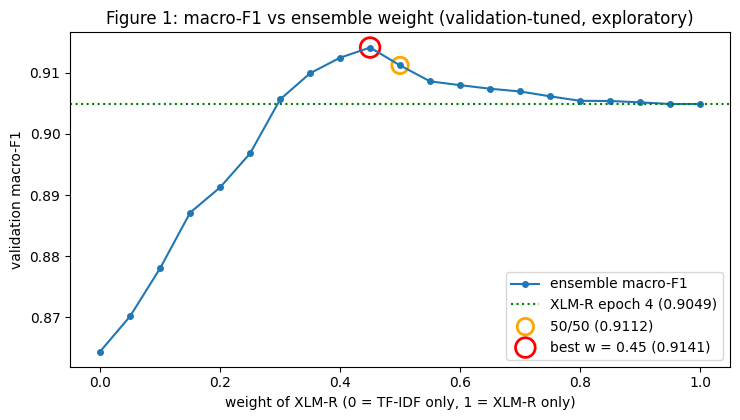

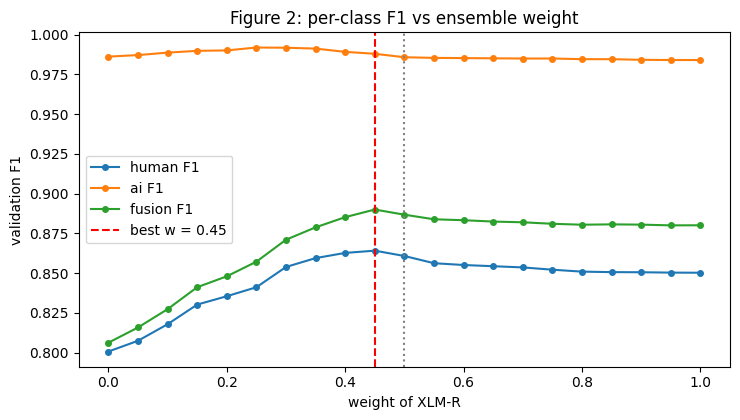

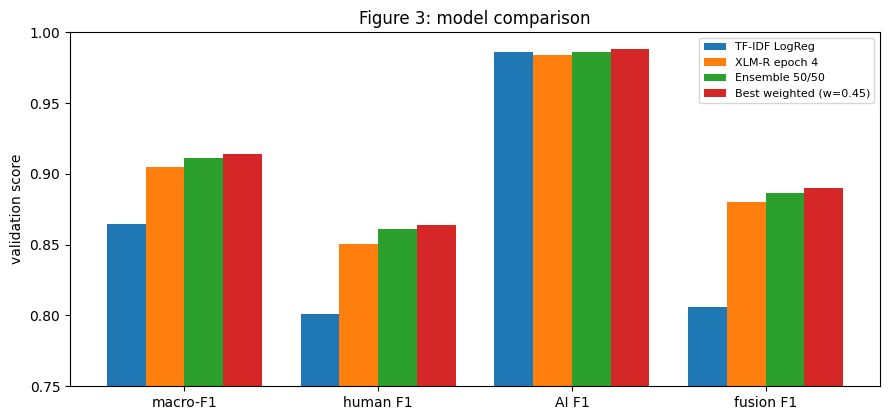

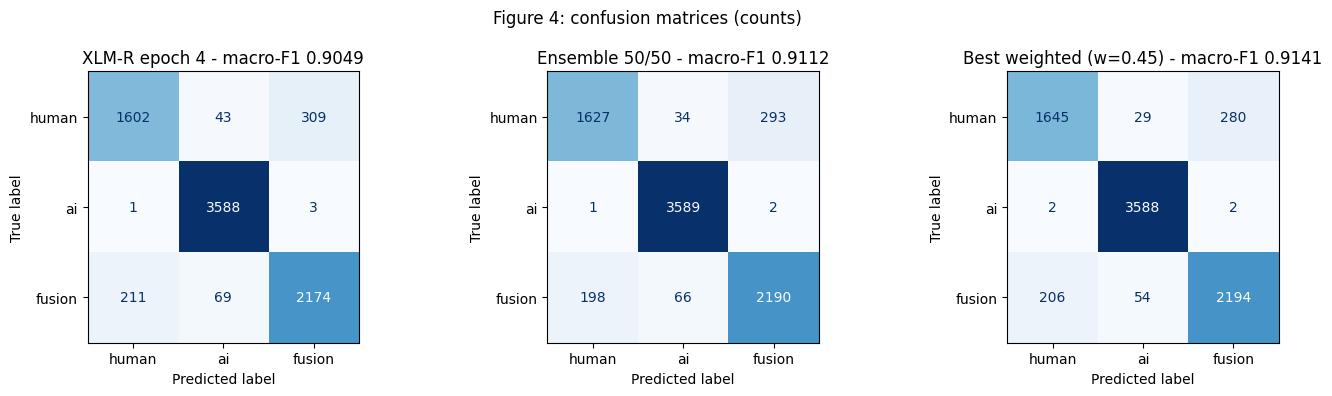

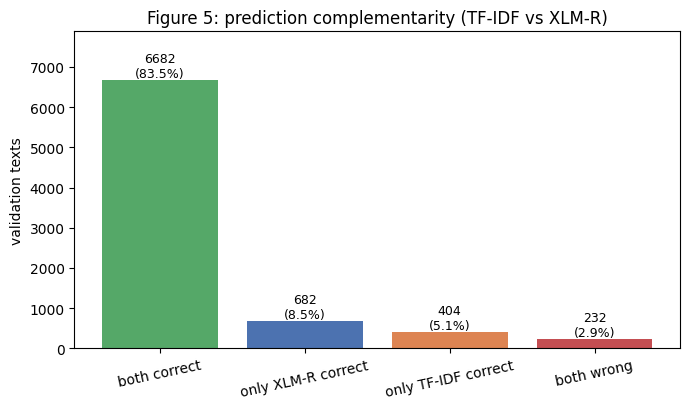

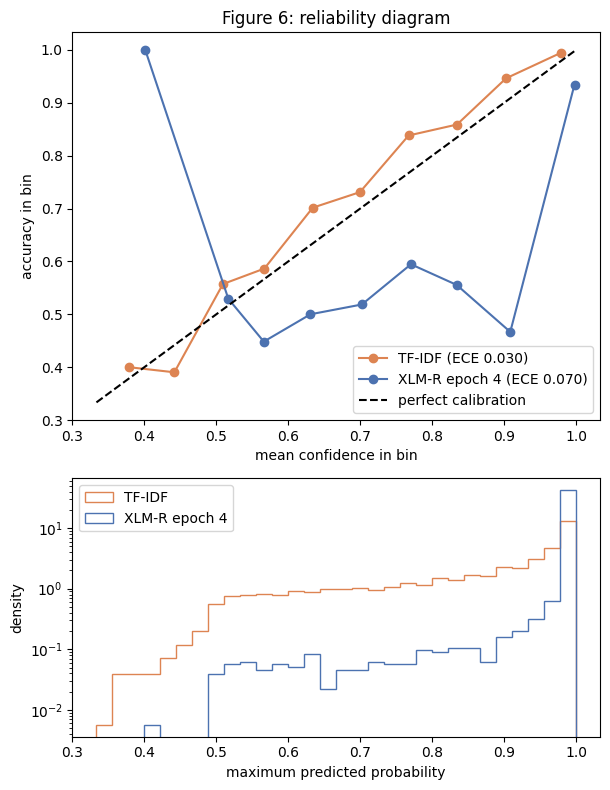

In [13]:
HL = "#4C72B0"; wb = sweep.set_index("w_xlmr")
fig, ax = plt.subplots(figsize=(7.5, 4.3)); ax.plot(sweep.w_xlmr, sweep.macro_f1, marker="o", ms=4, label="ensemble macro-F1")
ax.axhline(M_x["macro_f1"], color="green", ls=":", label=f"XLM-R epoch 4 ({M_x['macro_f1']:.4f})")
ax.scatter([0.5], [wb.loc[0.5, "macro_f1"]], s=140, facecolors="none", edgecolors="orange", linewidths=2, label=f"50/50 ({wb.loc[0.5, 'macro_f1']:.4f})")
ax.scatter([W_BEST], [M_best["macro_f1"]], s=200, facecolors="none", edgecolors="red", linewidths=2, label=f"best w = {W_BEST:.2f} ({M_best['macro_f1']:.4f})")
ax.set_xlabel("weight of XLM-R (0 = TF-IDF only, 1 = XLM-R only)"); ax.set_ylabel("validation macro-F1"); ax.set_title("Figure 1: macro-F1 vs ensemble weight (validation-tuned, exploratory)"); ax.legend(); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig1_macro_f1_vs_weight.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4.3))
for c in CLASSES: ax.plot(sweep.w_xlmr, sweep[f"f1_{c}"], marker="o", ms=4, label=f"{c} F1")
ax.axvline(0.5, color="gray", ls=":"); ax.axvline(W_BEST, color="red", ls="--", label=f"best w = {W_BEST:.2f}"); ax.set_xlabel("weight of XLM-R"); ax.set_ylabel("validation F1"); ax.set_title("Figure 2: per-class F1 vs ensemble weight"); ax.legend(); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig2_per_class_f1_vs_weight.png", dpi=150); plt.show()

labs = list(SYS); keys = ["macro_f1", "f1_human", "f1_ai", "f1_fusion"]; x = np.arange(len(keys)); fig, ax = plt.subplots(figsize=(9, 4.3))
for i, k in enumerate(labs): ax.bar(x + (i - 1.5) * 0.2, [SYS[k][1][q] for q in keys], 0.2, label=k.split(" (")[0] if "Best" not in k else f"Best weighted (w={W_BEST:.2f})")
ax.set_xticks(x); ax.set_xticklabels(["macro-F1", "human F1", "AI F1", "fusion F1"]); ax.set_ylim(0.75, 1.0); ax.set_ylabel("validation score"); ax.set_title("Figure 3: model comparison"); ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig3_model_comparison.png", dpi=150); plt.show()

from sklearn.metrics import ConfusionMatrixDisplay
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for a, p, t in [(axs[0], pred_x, "XLM-R epoch 4"), (axs[1], pred_eq, "Ensemble 50/50"), (axs[2], pred_best, f"Best weighted (w={W_BEST:.2f})")]:
    ConfusionMatrixDisplay(conf_mat(yva, p), display_labels=CLASSES).plot(cmap="Blues", ax=a, colorbar=False); a.set_title(f"{t} - macro-F1 {metrics(yva, p)['macro_f1']:.4f}")
plt.suptitle("Figure 4: confusion matrices (counts)"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig4_confusion_matrices.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.2)); bars = ax.bar(order, cat_tab.values, color=["#55A868", "#4C72B0", "#DD8452", "#C44E52"])
for b_, v in zip(bars, cat_tab.values): ax.text(b_.get_x() + b_.get_width() / 2, v, f"{v}\n({v / n:.1%})", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, cat_tab.max() * 1.18); ax.set_ylabel("validation texts"); ax.set_title("Figure 5: prediction complementarity (TF-IDF vs XLM-R)"); plt.xticks(rotation=12); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig5_complementarity.png", dpi=150); plt.show()

fig, ax = plt.subplots(2, 1, figsize=(6.2, 8), gridspec_kw={"height_ratios": [3, 2]})
for P, nm, col in [(Pv_t, "TF-IDF", "#DD8452"), (Pv_x, "XLM-R epoch 4", "#4C72B0")]:
    r = reliability(P, yva); ax[0].plot(r.confidence, r.accuracy, marker="o", color=col, label=f"{nm} (ECE {ece(P, yva):.3f})"); ax[1].hist(P.max(1), bins=30, range=(1 / 3, 1), histtype="step", color=col, label=nm, density=True)
ax[0].plot([1 / 3, 1], [1 / 3, 1], "k--", label="perfect calibration"); ax[0].set_xlabel("mean confidence in bin"); ax[0].set_ylabel("accuracy in bin"); ax[0].set_title("Figure 6: reliability diagram"); ax[0].legend()
ax[1].set_xlabel("maximum predicted probability"); ax[1].set_ylabel("density"); ax[1].set_yscale("log"); ax[1].legend(); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig6_calibration.png", dpi=150); plt.show()

## 14. Statistical comparison
Paired comparison of the encoder with each ensemble on the same 8,000 texts. The exact McNemar (sign) test compares **error rates** (how many texts each system gets right or wrong), which is not the same as testing a **macro-F1** difference; the paired bootstrap interval is a descriptive measure of the macro-F1 difference. Because the best weight and the epoch were chosen on this same validation set, p-values and intervals for the tuned ensemble are optimistic and must not be read as significance claims.

In [14]:
def mcnemar(ok_a, ok_b):
    b_ = int((ok_a & ~ok_b).sum()); c_ = int((~ok_a & ok_b).sum()); return b_, c_, (binomtest(b_, b_ + c_, 0.5).pvalue if b_ + c_ else 1.0)
def fast_mf1(y, p): cm = conf_mat(y, p); tp = np.diag(cm); pr = tp / np.maximum(cm.sum(0), 1); rc = tp / np.maximum(cm.sum(1), 1); return (2 * pr * rc / np.maximum(pr + rc, 1e-12)).mean()
rb = np.random.default_rng(SEED); BOOT = rb.integers(0, n, size=(N_BOOT, n)); stat_rows = []
for nm, p, okk in [("Ensemble 50/50", pred_eq, ok_eq), (f"Best weighted (w={W_BEST:.2f}, tuned on validation)", pred_best, ok_best)]:
    fixed, broken, pv = mcnemar(okk, ok_x); d = np.array([fast_mf1(yva[i], p[i]) - fast_mf1(yva[i], pred_x[i]) for i in BOOT]); lo, hi = np.percentile(d, [2.5, 97.5])
    stat_rows.append({"ensemble": nm, "fixed_vs_xlmr": fixed, "broken_vs_xlmr": broken, "McNemar_exact_p": pv, "macroF1_diff": fast_mf1(yva, p) - fast_mf1(yva, pred_x), "bootstrap_95CI_low": lo, "bootstrap_95CI_high": hi})
stats_df = pd.DataFrame(stat_rows); display(stats_df.round(4))
print("Bootstrap: 2000 resamples of the validation texts. Interpret with caution: weight and epoch were selected on this data; a confidence interval that includes 0 means the difference cannot be distinguished from noise here.")

,ensemble,fixed_vs_xlmr,broken_vs_xlmr,McNemar_exact_p,macroF1_diff,bootstrap_95CI_low,bootstrap_95CI_high
0,Ensemble 50/50,47,5,0.0,0.0063,0.0042,0.0085
1,"Best weighted (w=0.45, tuned on validation)",104,41,0.0,0.0092,0.0059,0.0127


Bootstrap: 2000 resamples of the validation texts. Interpret with caution: weight and epoch were selected on this data; a confidence interval that includes 0 means the difference cannot be distinguished from noise here.


## 15. Test predictions and submission
The selected ensemble is applied to the test probabilities. The XLM-R test rows are aligned by id; the TF-IDF test rows follow `test.csv` order (see the alignment note in section 6). Two files are written: the **validation-tuned** best weight and the **fixed 50/50** ensemble (defined in advance). Nothing is submitted to Kaggle automatically.

In [15]:
def write_submission(P, name):
    pred = P.argmax(1); assert len(pred) == 25000
    s = pd.DataFrame({"id": test.id.values, "label": [id2label[i] for i in pred]}).set_index("id").loc[sub_tmpl.id].reset_index()
    assert list(s.columns) == ["id", "label"] and len(s) == 25000 and s.id.is_unique and s.id.tolist() == sub_tmpl.id.tolist() and s.label.notna().all() and s.label.isin(CLASSES).all()
    s.to_csv(f"{OUT_DIR}/{name}.csv", index=False); print(f"saved {name}.csv | predicted label shares: {s.label.value_counts(normalize=True).round(3).to_dict()}"); return s
P_te_equal = 0.5 * Pt_x + 0.5 * Pt_t; P_te_best = W_BEST * Pt_x + (1 - W_BEST) * Pt_t
s_best = write_submission(P_te_best, "sub_experiment_3_ensemble"); s_eq = write_submission(P_te_equal, "sub_experiment_3_ensemble_5050")
print("test predictions that differ between the 50/50 file and the best-weight file:", int((P_te_equal.argmax(1) != P_te_best.argmax(1)).sum()))

saved sub_experiment_3_ensemble.csv | predicted label shares: {'ai': 0.526, 'fusion': 0.238, 'human': 0.236}
saved sub_experiment_3_ensemble_5050.csv | predicted label shares: {'ai': 0.528, 'fusion': 0.242, 'human': 0.23}
test predictions that differ between the 50/50 file and the best-weight file: 296


## 16. Save experiment artifacts

In [16]:
np.savez(f"{OUT_DIR}/experiment_3_ensemble_probs.npz", va_ids=va_df.id.values.astype(str), test_ids=test.id.values.astype(str), yva=yva, P_va=P_best.astype(np.float32), P_te=P_te_best.astype(np.float32), classes=np.array(CLASSES),
         w_selected=np.array(W_BEST), P_va_xlmr=Pv_x.astype(np.float32), P_te_xlmr=Pt_x.astype(np.float32), P_va_tfidf=Pv_t.astype(np.float32), P_te_tfidf=Pt_t.astype(np.float32),
         P_va_equal=P_equal.astype(np.float32), P_te_equal=P_te_equal.astype(np.float32))
chk = np.load(f"{OUT_DIR}/experiment_3_ensemble_probs.npz", allow_pickle=True); assert chk["P_va"].shape == (8000, 3) and chk["P_te"].shape == (25000, 3) and list(chk["classes"]) == CLASSES
json.dump(dict(experiment="TF-IDF + XLM-R epoch-4 probability ensemble; no model trained", selected_weight_xlmr=W_BEST, selected_weight_tuned_on_validation=True, equal_weight=0.5,
               tfidf_archive=TFIDF_FILE, xlmr_archive=XLMR_FILE, tfidf_alignment=TFIDF_ALIGNMENT, seed=SEED, validation_fingerprint=FINGERPRINT, class_order=CLASSES,
               scores=dict(tfidf_macro_f1=M_t["macro_f1"], xlmr_epoch4_macro_f1=M_x["macro_f1"], equal_5050_macro_f1=M_eq["macro_f1"], best_weighted_macro_f1_validation_tuned=M_best["macro_f1"],
                           crossfitted_weight_macro_f1=M_cf["macro_f1"], calibrated_crossfitted_5050_macro_f1=M_cal["macro_f1"]),
               holdout_diagnostic=dict(n_repeats=N_REPEATS, mean_selected_minus_encoder=float(rep_df.sel_minus_enc.mean()), mean_equal_minus_encoder=float(rep_df.eq_minus_enc.mean()), mean_selected_minus_equal=float(rep_df.sel_minus_eq.mean())),
               note="validation was also used to select the encoder epoch and the ensemble weight; scores for tuned configurations are optimistic"), open(f"{OUT_DIR}/experiment_3_config.json", "w"), indent=1, default=str)
print(sorted(os.listdir(OUT_DIR)))

['experiment_3_class_metrics.csv', 'experiment_3_config.json', 'experiment_3_ensemble_probs.npz', 'experiment_3_error_analysis.csv', 'experiment_3_model_comparison.csv', 'experiment_3_weight_search.csv', 'fig1_macro_f1_vs_weight.png', 'fig2_per_class_f1_vs_weight.png', 'fig3_model_comparison.png', 'fig4_confusion_matrices.png', 'fig5_complementarity.png', 'fig6_calibration.png', 'sub_experiment_3_ensemble.csv', 'sub_experiment_3_ensemble_5050.csv']


## 17. Conclusions
Generated from the measured results only (nothing typed in). Add your own interpretation below.

In [17]:
print(f"Reference encoder (epoch 4): {M_x['macro_f1']:.4f}. TF-IDF: {M_t['macro_f1']:.4f}.")
print(f"Equal-weight ensemble: {M_eq['macro_f1']:.4f} ({M_eq['macro_f1'] - M_x['macro_f1']:+.4f} vs the encoder) -> " + ("it improved on the encoder alone." if M_eq['macro_f1'] > M_x['macro_f1'] else "it did NOT improve on the encoder alone."))
print(f"Best weight on validation: w = {W_BEST:.2f} -> {M_best['macro_f1']:.4f} ({M_best['macro_f1'] - M_x['macro_f1']:+.4f} vs the encoder, {M_best['macro_f1'] - M_eq['macro_f1']:+.4f} vs 50/50); tuned on the validation set, so optimistic." + (" The encoder alone is preferable in this experiment." if W_BEST == 1.0 else ""))
print(f"Held-out diagnostic (weight chosen on one half, scored on the other, {N_REPEATS} repeats): tuned - encoder {rep_df.sel_minus_enc.mean():+.4f} (std {rep_df.sel_minus_enc.std():.4f}), fixed 50/50 - encoder {rep_df.eq_minus_enc.mean():+.4f}, tuned - 50/50 {rep_df.sel_minus_eq.mean():+.4f}. Equal weights were " + ("sufficient (tuning added little)." if abs(rep_df.sel_minus_eq.mean()) < 0.002 else "not clearly sufficient."))
print(f"Complementarity: TF-IDF is right when the encoder is wrong on {cat_tab['only TF-IDF correct']} texts ({cat_tab['only TF-IDF correct'] / n:.1%}); the 50/50 ensemble fixes {int((va_df.equal_vs_xlmr == 'fixed by 50/50').sum())} and breaks {int((va_df.equal_vs_xlmr == 'broken by 50/50').sum())} encoder decisions (McNemar p = {stats_df.McNemar_exact_p.iloc[0]:.3f}; bootstrap 95% interval of the macro-F1 difference [{stats_df.bootstrap_95CI_low.iloc[0]:+.4f}, {stats_df.bootstrap_95CI_high.iloc[0]:+.4f}]).")
print(f"Fusion: F1 {M_x['f1_fusion']:.4f} (encoder) -> {M_eq['f1_fusion']:.4f} (50/50) -> {M_best['f1_fusion']:.4f} (best weight); fusion recall {M_x['recall_fusion']:.4f} -> {M_eq['recall_fusion']:.4f} -> {M_best['recall_fusion']:.4f}; human F1 {M_x['f1_human']:.4f} -> {M_eq['f1_human']:.4f} -> {M_best['f1_human']:.4f}.")
print(f"Confidence: mean max probability XLM-R {Pv_x.max(1).mean():.3f} vs TF-IDF {Pv_t.max(1).mean():.3f}; ECE {ece(Pv_x, yva):.3f} vs {ece(Pv_t, yva):.3f}; on disagreements the 50/50 ensemble follows XLM-R {follow_x:.1%} of the time.")
print("Limitations: validation was used to select the encoder epoch AND the ensemble weight (optimistic scores); the held-out halves are not independent of the epoch selection; validation may contain siblings of training texts; the TF-IDF archive lacked ids (indirect alignment checks); single run, no test labels.")

Reference encoder (epoch 4): 0.9049. TF-IDF: 0.8644.
Equal-weight ensemble: 0.9112 (+0.0063 vs the encoder) -> it improved on the encoder alone.
Best weight on validation: w = 0.45 -> 0.9141 (+0.0092 vs the encoder, +0.0029 vs 50/50); tuned on the validation set, so optimistic.
Held-out diagnostic (weight chosen on one half, scored on the other, 100 repeats): tuned - encoder +0.0084 (std 0.0028), fixed 50/50 - encoder +0.0064, tuned - 50/50 +0.0020. Equal weights were not clearly sufficient.
Complementarity: TF-IDF is right when the encoder is wrong on 404 texts (5.1%); the 50/50 ensemble fixes 47 and breaks 5 encoder decisions (McNemar p = 0.000; bootstrap 95% interval of the macro-F1 difference [+0.0042, +0.0085]).
Fusion: F1 0.8802 (encoder) -> 0.8868 (50/50) -> 0.8901 (best weight); fusion recall 0.8859 -> 0.8924 -> 0.8941; human F1 0.8503 -> 0.8608 -> 0.8642.
Confidence: mean max probability XLM-R 0.990 vs TF-IDF 0.856; ECE 0.070 vs 0.030; on disagreements the 50/50 ensemble follo

### Experiment 3 — Conclusions

We investigated whether combining TF-IDF Logistic Regression and the best XLM-RoBERTa checkpoint (epoch 4) improves three-class text classification.

Equal-weight probability averaging increased validation macro-F1 from **0.9049 to 0.9112**, demonstrating that TF-IDF provides complementary information despite its lower standalone performance (0.8644).

Optimizing ensemble weights further improved macro-F1 to **0.9141**, with the best validation combination assigning 45% weight to XLM-RoBERTa and 55% to TF-IDF. This represents a gain of **0.0092** over the encoder alone.

The ensemble also improved classification of the most challenging classes. Human F1 increased from 0.8503 to 0.8642, while fusion F1 increased from 0.8802 to 0.8901 and fusion recall from 0.8859 to 0.8941.

The models showed complementary errors: TF-IDF correctly classified 404 of the 636 examples misclassified by XLM-RoBERTa. However, the equal-weight ensemble corrected only 47 encoder errors, partly because XLM-RoBERTa produced substantially more confident predictions (mean maximum probability 0.990 versus 0.856).

Additional calibration analysis suggested further potential improvement, achieving a cross-fitted macro-F1 of 0.9177. However, this result remains exploratory because the validation set was also used to select the encoder checkpoint.

Overall, **the ensemble hypothesis was supported**. Combining lexical TF-IDF features with contextual transformer predictions improved validation performance, especially for human and fusion texts.

For a reproducible submission, the validation-optimized weighted ensemble (45% XLM-RoBERTa, 55% TF-IDF) is a candidate final model. Its performance should be confirmed on the competition leaderboard, since validation-based weight tuning may introduce optimistic bias.